# **Group4-day2-assignment**
## Predicting Floor Area from Fuel Consumption – Model Training

## 1. Objective

The objective is to train a machine-learning model that answers the question:

> *"If this is the fuel consumption of a home, how big is it?"*

We predict the **floor area band** of residential properties from their annual **gas** and **electricity** consumption, helped by a few basic building characteristics.

**Target variable:** `FLOOR_AREA_BAND`

| Band | Floor area |
|---|---|
| 1 | up to 50 m² |
| 2 | 51 – 100 m² |
| 3 | 101 – 150 m² |
| 4 | 151 – 200 m² |
| 5 | over 200 m² |

*(Band ranges as defined in the NEED dataset documentation. Check them against your dataset's documentation.)*

**Input features:**

* Fuel consumption: annual gas (`Gcons2024`) and electricity (`Econs2024`) consumption in kWh.
* Building characteristics: property type, age band, region and main heating fuel.

Because the target is a **band** (a category), this is a **classification** problem, not regression.

## 2. Modelling Workflow

1. Load the prepared dataset and explore how fuel consumption changes with floor area.
2. Define the input features and target, and check for leakage.
3. Split the data into training and test sets (stratified by band).
4. Build a preprocessing pipeline for numerical and categorical features.
5. Establish a baseline model.
6. Train and compare multiple classification models using cross-validation.
7. Test which inputs matter: gas only, gas + electricity, or fuel + building information.
8. Handle the class imbalance and tune the best model.
9. Evaluate the selected model on the test set.
10. Explain the model with permutation importance.
11. Save the final model and use it as a design tool: *"if fuel use is X, floor area is Y"*.

## 3. Evaluation Metric

We will use the **macro F1-score** as the primary metric. It averages the F1-score of each band **equally**, so the rare large homes (bands 4 and 5) count as much as the common ones. Higher is better (1.0 = perfect).

We also report:

* **Accuracy:** share of homes placed in exactly the right band.
* **Within ±1 band:** share of homes placed in the right band or a neighbouring one. Bands are ordered, so being one band off is a much smaller mistake than being three bands off.

# 0. Setup
## 0.1 Libraries

In [1]:
# Only needed in a new environment: remove the "#" and run this cell once.
# %pip install pandas numpy matplotlib seaborn scikit-learn joblib

In [2]:
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib   # to save and load trained models

In [3]:
# --- Folders (this notebook lives in notebooks/, so we go up one level with "..") ---
DATA_DIR = Path("../data")
FIG_DIR = Path("../figures")
MODEL_DIR = Path("../models")   # trained models will be saved here
for folder in [FIG_DIR, MODEL_DIR]:
    folder.mkdir(exist_ok=True)

# --- Display and plot settings ------------------------------------------------
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", "{:,.3f}".format)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (10, 5)

# The same seed everywhere: same splits, same "random" models, same results for everybody
RANDOM_STATE = 42


def save_fig(name):
    # Save the current figure as a PNG inside FIG_DIR
    path = FIG_DIR / f"{name}.png"
    plt.savefig(path, dpi=150, bbox_inches="tight")
    print(f"Figure saved to {path}")

## 0.2 Dataset: domestic energy consumption (from Day 1)

In [4]:
data_path = DATA_DIR / "anon2026_50k_cleaned.csv"

if not data_path.exists():
    raise FileNotFoundError(
        f"{data_path} not found. Copy anon2026_50k_cleaned.csv into the data/ folder of the repository."
    )

df = pd.read_csv(data_path)
print(f"Homes: {df.shape[0]:,} rows x {df.shape[1]} columns")
df[["FLOOR_AREA_BAND", "Gcons2024", "Econs2024", "PROP_TYPE", "PROP_AGE_BAND", "REGION", "MAIN_HEAT_FUEL"]].head()

Homes: 49,998 rows x 96 columns


,FLOOR_AREA_BAND,Gcons2024,Econs2024,PROP_TYPE,PROP_AGE_BAND,REGION,MAIN_HEAT_FUEL
0,2,"6,600.000","3,100.000",Semi detached,3,E12000004,1
1,3,"13,500.000","4,200.000",Mid terrace,1,E12000007,1
2,3,"9,700.000","2,400.000",Detached,4,E12000005,1
3,2,"5,700.000","3,000.000",Semi detached,4,E12000004,1
4,2,"11,500.000","1,700.000",Bungalow,2,E12000008,1


In [5]:
# Readable names for the codes used in the dataset
FLOOR_AREA_LABELS = {1: "up to 50 m²", 2: "51-100 m²", 3: "101-150 m²", 4: "151-200 m²", 5: "over 200 m²"}
REGION_NAMES = {
    "E12000001": "North East", "E12000002": "North West", "E12000003": "Yorkshire and The Humber",
    "E12000004": "East Midlands", "E12000005": "West Midlands", "E12000006": "East of England",
    "E12000007": "London", "E12000008": "South East", "E12000009": "South West", "W92000004": "Wales",
}

# 1. Exploring the data
## 1.1 How does fuel consumption change with floor area?

In [6]:
band_summary = df.groupby("FLOOR_AREA_BAND").agg(
    homes=("FLOOR_AREA_BAND", "size"),
    median_gas_kWh=("Gcons2024", "median"),
    median_elec_kWh=("Econs2024", "median"),
)
band_summary.insert(0, "floor area", band_summary.index.map(FLOOR_AREA_LABELS))
band_summary["share (%)"] = band_summary["homes"] / band_summary["homes"].sum() * 100
band_summary

,floor area,homes,median_gas_kWh,median_elec_kWh,share (%)
FLOOR_AREA_BAND,,,,,
1,up to 50 m²,8373,"5,700.000","2,000.000",16.747
2,51-100 m²,24567,"9,000.000","2,400.000",49.136
3,101-150 m²,12938,"12,100.000","2,900.000",25.877
4,151-200 m²,2644,"16,200.000","3,700.000",5.288
5,over 200 m²,1476,"23,000.000","5,300.000",2.952


Figure saved to ..\figures\03_01_fuel_by_floor_area_band.png


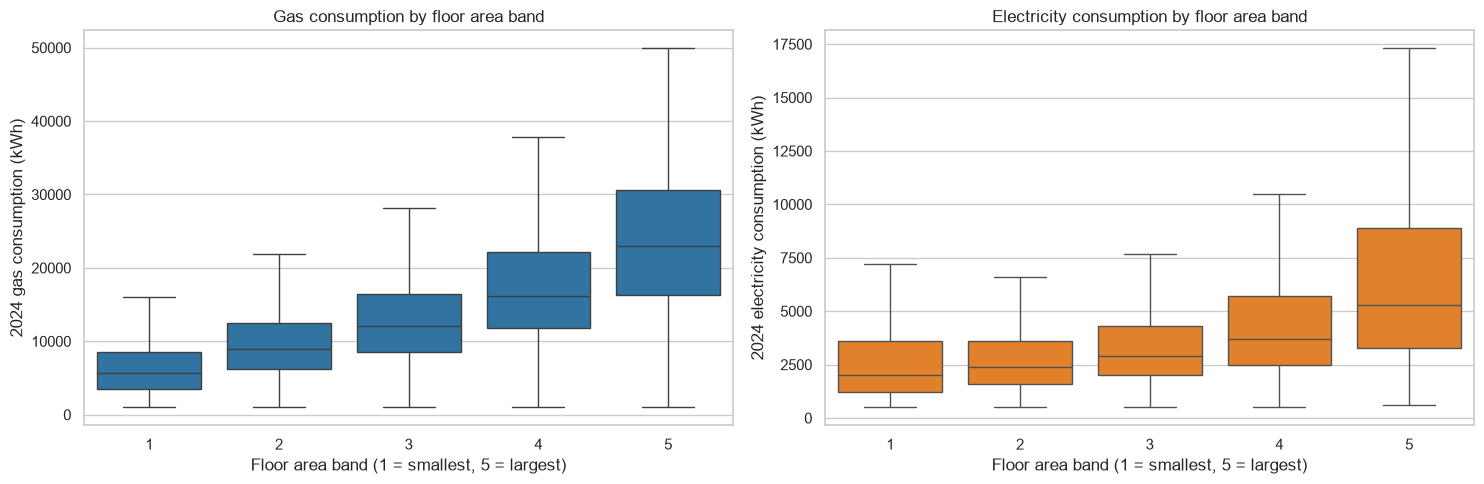

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.boxplot(data=df, x="FLOOR_AREA_BAND", y="Gcons2024", showfliers=False, color="tab:blue", ax=axes[0])
axes[0].set_title("Gas consumption by floor area band")
axes[0].set_xlabel("Floor area band (1 = smallest, 5 = largest)")
axes[0].set_ylabel("2024 gas consumption (kWh)")

sns.boxplot(data=df, x="FLOOR_AREA_BAND", y="Econs2024", showfliers=False, color="tab:orange", ax=axes[1])
axes[1].set_title("Electricity consumption by floor area band")
axes[1].set_xlabel("Floor area band (1 = smallest, 5 = largest)")
axes[1].set_ylabel("2024 electricity consumption (kWh)")

plt.tight_layout()
save_fig("03_01_fuel_by_floor_area_band")
plt.show()

**Reading the results:** the median gas consumption grows steadily with the size of the home: from about **5,700 kWh** for band 1 to **23,000 kWh** for band 5, roughly **4 times more**. Electricity grows too, but less (from 2,000 to 5,300 kWh), because much of it goes to appliances and lighting rather than heating space. The boxes **overlap**, though: a 9,000 kWh home can be band 1, 2 or 3.

Figure saved to ..\figures\03_02_gas_vs_elec_by_band.png


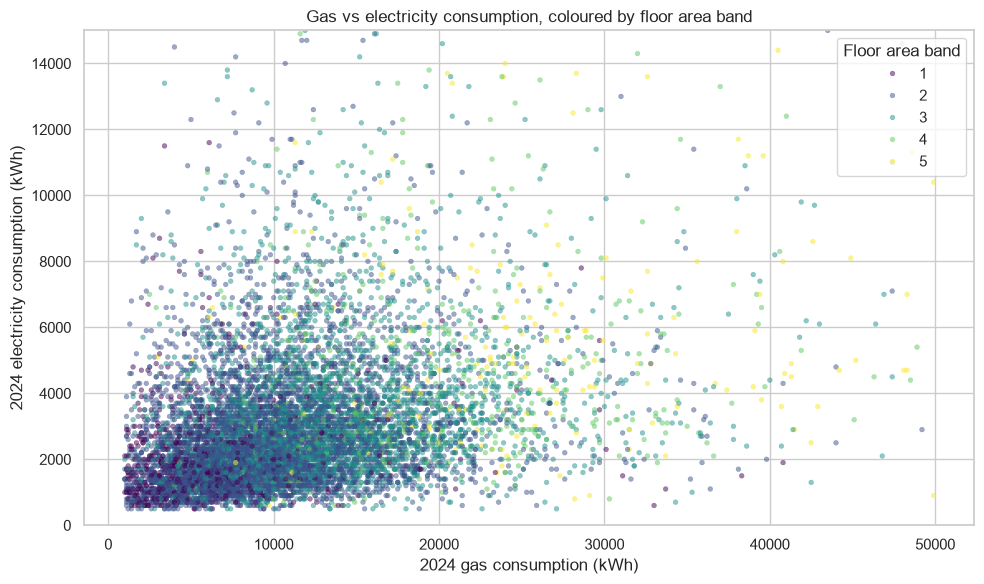

In [8]:
# A random sample of 10,000 homes keeps the plot readable
sample = df.dropna(subset=["Gcons2024", "Econs2024"]).sample(10_000, random_state=RANDOM_STATE)

fig, ax = plt.subplots(figsize=(10, 6))
sns.scatterplot(data=sample, x="Gcons2024", y="Econs2024", hue="FLOOR_AREA_BAND",
                palette="viridis", alpha=0.5, s=12, edgecolor=None, ax=ax)
ax.set_title("Gas vs electricity consumption, coloured by floor area band")
ax.set_xlabel("2024 gas consumption (kWh)")
ax.set_ylabel("2024 electricity consumption (kWh)")
ax.set_ylim(0, 15_000)
ax.legend(title="Floor area band")
plt.tight_layout()
save_fig("03_02_gas_vs_elec_by_band")
plt.show()

Small homes (dark purple) cluster at the **bottom left**, and large homes (yellow) spread to the **top right**. The colours **overlap a lot**, though: two homes with the same consumption can have very different sizes because of insulation, number of occupants and heating habits. So we should expect a useful model, **not a perfect one**.

# 2. Features, target and train/test split
## 2.1 Choosing the features (and avoiding leakage)

In [9]:
TARGET = "FLOOR_AREA_BAND"

fuel_features = ["Gcons2024", "Econs2024"]                       # what the question is about
building_numeric = ["PROP_AGE_BAND"]                             # ordered codes 1-4: kept as a number
building_nominal = ["PROP_TYPE", "REGION", "MAIN_HEAT_FUEL"]     # categories without order: one-hot

numeric_features = fuel_features + building_numeric
nominal_features = building_nominal

# Only homes with a 2024 gas reading (the main input)
model_df = df.dropna(subset=["Gcons2024", TARGET]).copy()

X = model_df[numeric_features + nominal_features + ["COUNCIL_TAX_BAND"]]   # council tax: only for the experiment in 3.2
y = model_df[TARGET].astype(int)

print(f"Homes with a 2024 gas reading: {len(model_df):,}")
print("Numeric:", numeric_features)
print("Nominal:", nominal_features)

Homes with a 2024 gas reading: 39,502
Numeric: ['Gcons2024', 'Econs2024', 'PROP_AGE_BAND']
Nominal: ['PROP_TYPE', 'REGION', 'MAIN_HEAT_FUEL']


⚠️ **Leakage check:** `FLOOR_AREA_BAND` is the answer, so it must never be an input. `COUNCIL_TAX_BAND` is not the answer, but it is set largely by the **size and value** of the home, so it is almost a proxy for floor area. We keep it out of the main model, because the question is *"what does the fuel consumption tell us?"*. We only use it once, in section 3.2, to see how much it would inflate the score.

## 2.2 Train/test split

In [10]:
from sklearn.model_selection import train_test_split, StratifiedKFold

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,              # 20% for the test set
    stratify=y,                 # keep the same share of each band in train and test
    random_state=RANDOM_STATE,
)

# The stratified 5-fold splitter we will use for all models
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

print(f"Training set: {len(X_train):,} homes")
print(f"Test set:     {len(X_test):,} homes (locked away until section 4!)")

pd.DataFrame({
    "train (%)": y_train.value_counts(normalize=True).sort_index() * 100,
    "test (%)": y_test.value_counts(normalize=True).sort_index() * 100,
}).round(1)

Training set: 31,601 homes
Test set:     7,901 homes (locked away until section 4!)


,train (%),test (%)
FLOOR_AREA_BAND,,
1,9.800,9.800
2,53.000,53.000
3,29.500,29.500
4,5.500,5.500
5,2.200,2.200


The classes are **imbalanced**: among homes with a gas reading, band 2 alone is **53%** of all homes, while band 5 is only about **2%**. A model that always answers "band 2" would already be right about half the time. That's why we use **macro F1** and not only accuracy.

## 2.3 Preprocessing pipeline

In [11]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder


def make_pipeline_for(model, numeric=numeric_features, nominal=nominal_features, scale=True):
    # Build preprocessing + model as one Pipeline.
    #   model   : any scikit-learn classifier
    #   numeric : numeric columns (missing values -> median, optionally scaled)
    #   nominal : categorical columns (missing values -> most frequent, then one-hot encoded)
    #   scale   : True for linear models / KNN, False for trees
    numeric_steps = [("imputer", SimpleImputer(strategy="median"))]
    if scale:
        numeric_steps.append(("scaler", StandardScaler()))

    transformers = [("num", Pipeline(numeric_steps), numeric)]
    if nominal:
        transformers.append(("nom", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
        ]), nominal))

    return Pipeline([
        ("preprocess", ColumnTransformer(transformers)),
        ("model", model),
    ])

# 3. Training and comparing models
## 3.1 The model zoo

In [12]:
from sklearn.model_selection import cross_validate


def compare_models(pipelines, X, y, cv, scoring):
    # Cross-validate every pipeline and return one row of results per model.
    #   scoring: dict {display name: scikit-learn scorer name}
    rows = []
    for name, pipeline in pipelines.items():
        start = time.time()
        res = cross_validate(pipeline, X, y, cv=cv, scoring=scoring, n_jobs=-1)  # n_jobs=-1: use all CPU cores
        row = {"model": name}
        for metric in scoring:
            row[f"{metric} mean"] = res[f"test_{metric}"].mean()
            row[f"{metric} std"] = res[f"test_{metric}"].std()
        row["fit time (s)"] = res["fit_time"].mean()
        rows.append(row)
        print(f"{name:<26} done in {time.time() - start:5.1f} s")
    return pd.DataFrame(rows).set_index("model").sort_values(f"{list(scoring)[0]} mean", ascending=False)


scoring = {"macro F1": "f1_macro", "accuracy": "accuracy"}

In [13]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier

classification_pipelines = {
    "Baseline (most frequent)": make_pipeline_for(DummyClassifier(strategy="most_frequent")),
    "Logistic regression": make_pipeline_for(LogisticRegression(max_iter=2000)),
    "KNN (k=25)": make_pipeline_for(KNeighborsClassifier(n_neighbors=25)),
    "Decision tree": make_pipeline_for(DecisionTreeClassifier(max_depth=8, random_state=RANDOM_STATE), scale=False),
    "Random forest": make_pipeline_for(RandomForestClassifier(n_estimators=200, min_samples_leaf=5,
                                                              random_state=RANDOM_STATE), scale=False),
    "Gradient boosting": make_pipeline_for(HistGradientBoostingClassifier(random_state=RANDOM_STATE), scale=False),
}

classification_results = compare_models(classification_pipelines, X_train, y_train, cv, scoring)
classification_results

Baseline (most frequent)   done in   3.4 s
Logistic regression        done in   2.0 s
KNN (k=25)                 done in   2.6 s
Decision tree              done in   1.8 s
Random forest              done in   4.3 s
Gradient boosting          done in   2.6 s


,macro F1 mean,macro F1 std,accuracy mean,accuracy std,fit time (s)
model,,,,,
Gradient boosting,0.505,0.012,0.665,0.005,1.081
Random forest,0.495,0.008,0.661,0.004,2.684
KNN (k=25),0.486,0.008,0.657,0.003,0.065
Decision tree,0.486,0.013,0.656,0.003,0.114
Logistic regression,0.482,0.013,0.661,0.005,0.392
Baseline (most frequent),0.139,0.000,0.530,0.000,0.064


Figure saved to ..\figures\03_03_model_comparison.png


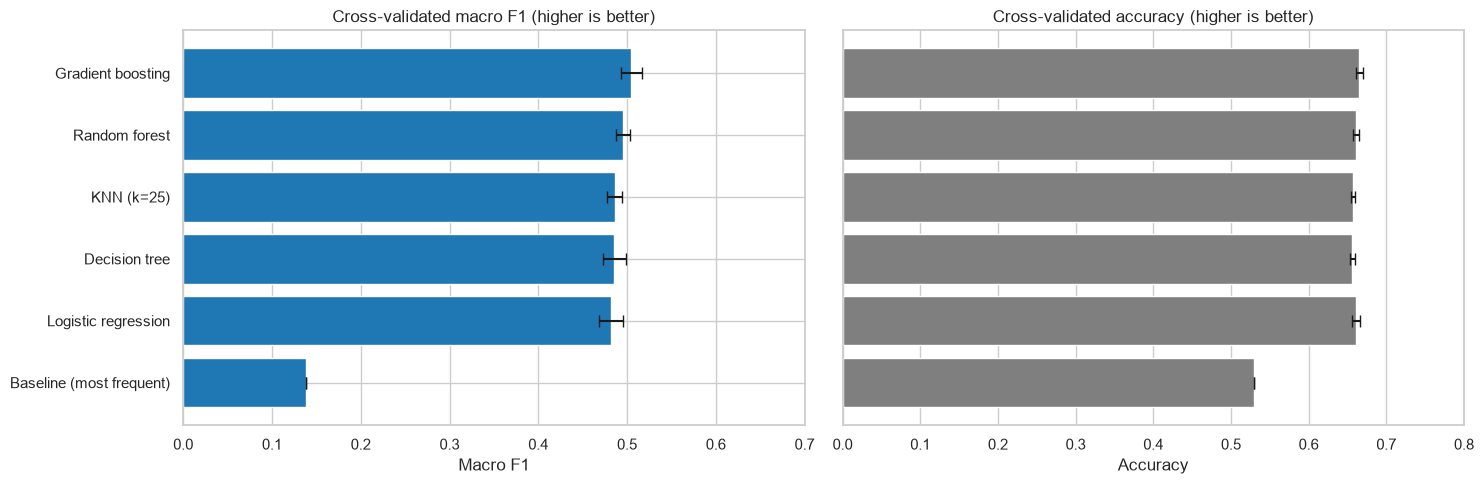

In [14]:
plot_data = classification_results.sort_values("macro F1 mean")

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# xerr = error bars of +/- one standard deviation across the 5 folds
axes[0].barh(plot_data.index, plot_data["macro F1 mean"], xerr=plot_data["macro F1 std"], color="tab:blue", capsize=4)
axes[0].set_xlim(0, 0.7)
axes[0].set_title("Cross-validated macro F1 (higher is better)")
axes[0].set_xlabel("Macro F1")

axes[1].barh(plot_data.index, plot_data["accuracy mean"], xerr=plot_data["accuracy std"], color="tab:grey", capsize=4)
axes[1].set_xlim(0, 0.8)
axes[1].set_title("Cross-validated accuracy (higher is better)")
axes[1].set_xlabel("Accuracy")
axes[1].set_yticks([])

plt.tight_layout()
save_fig("03_03_model_comparison")
plt.show()

**Reading the results:**

* Every real model beats the baseline by far: macro F1 rises from **0.14** to about **0.50**, and accuracy from **53%** to about **66%**.
* **Gradient boosting** is the best (macro F1 **0.505**), but the differences between the real models are small. Logistic regression is only 0.02 behind.
* When very different models all land at almost the same score, the limit is usually **the information in the data**, not the model. Fuel consumption says a lot about size, but not everything.

## 3.2 Experiment: which inputs matter?

How much can we say from **fuel consumption alone**? We train the same gradient boosting model on growing sets of inputs.

In [15]:
feature_sets = {
    "gas only": (["Gcons2024"], []),
    "gas + electricity": (fuel_features, []),
    "fuel + building info": (numeric_features, nominal_features),
    "fuel + building + council tax": (numeric_features, nominal_features + ["COUNCIL_TAX_BAND"]),
}

feature_pipelines = {
    name: make_pipeline_for(HistGradientBoostingClassifier(random_state=RANDOM_STATE),
                            numeric=num, nominal=nom, scale=False)
    for name, (num, nom) in feature_sets.items()
}

feature_results = compare_models(feature_pipelines, X_train, y_train, cv, scoring)
feature_results = feature_results.loc[list(feature_sets)]   # keep the order of the experiment
feature_results[["macro F1 mean", "macro F1 std", "accuracy mean"]]

gas only                   done in   1.8 s
gas + electricity          done in   0.6 s
fuel + building info       done in   1.5 s
fuel + building + council tax done in   2.2 s


,macro F1 mean,macro F1 std,accuracy mean
model,,,
gas only,0.254,0.006,0.547
gas + electricity,0.264,0.007,0.551
fuel + building info,0.505,0.012,0.665
fuel + building + council tax,0.629,0.011,0.725


**Reading the results:**

* **Fuel only** (gas, or gas + electricity) reaches a macro F1 of only about **0.26**, and electricity adds very little on top of gas.
* Adding basic **building information** almost **doubles** the score (**0.505**). Knowing that a home is a flat or a detached house tells the model what "normal" consumption looks like for that kind of home. 12,000 kWh is a lot for a flat but little for a detached house.
* Adding **council tax band** jumps to **0.63**. That is the "size proxy" effect from section 2.1: it tells the model the size almost directly. We leave it out to stay true to our question.

## 3.3 Handling the imbalance: `class_weight="balanced"`

By default every home counts the same during training, so the model mostly learns the common bands. `class_weight="balanced"` gives **more weight to rare bands** (4 and 5), so the model pays more attention to them.

In [16]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import f1_score, accuracy_score, recall_score

rows = []
for weight in [None, "balanced"]:
    pipe = make_pipeline_for(HistGradientBoostingClassifier(class_weight=weight, random_state=RANDOM_STATE), scale=False)
    pred = cross_val_predict(pipe, X_train, y_train, cv=cv, n_jobs=-1)   # out-of-fold predictions
    recalls = recall_score(y_train, pred, average=None)                 # recall of each band
    rows.append({
        "class_weight": str(weight),
        "accuracy": accuracy_score(y_train, pred),
        "macro F1": f1_score(y_train, pred, average="macro"),
        **{f"recall band {b}": r for b, r in zip(sorted(y_train.unique()), recalls)},
    })

pd.DataFrame(rows).set_index("class_weight")

,accuracy,macro F1,recall band 1,recall band 2,recall band 3,recall band 4,recall band 5
class_weight,,,,,,,
None,0.665,0.505,0.854,0.818,0.465,0.078,0.307
balanced,0.596,0.503,0.953,0.673,0.376,0.407,0.578


**Reading the results:** without weights, the model finds only **8%** of the band-4 homes and **31%** of the band-5 homes. With `class_weight="balanced"`, it finds **41%** and **58%**. The price is a lower accuracy (**67% → 60%**), because some band-2 and band-3 homes are now pushed into bigger bands. Macro F1 stays about the same.

🤔 **Think about it:** which mistake is worse for your use case, missing large homes, or over-estimating some medium ones? There is no single right answer; it depends on what the prediction is used for.

## 3.4 Tuning the best model

In [17]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "model__learning_rate": [0.05, 0.1],
    "model__max_leaf_nodes": [15, 31],
    "model__class_weight": [None, "balanced"],
}

start = time.time()
grid_search = GridSearchCV(
    make_pipeline_for(HistGradientBoostingClassifier(random_state=RANDOM_STATE), scale=False),
    param_grid,
    cv=cv,
    scoring="f1_macro",
    n_jobs=-1,
)
grid_search.fit(X_train, y_train)
print(f"Tried {len(grid_search.cv_results_['params'])} combinations x 5 folds in {time.time() - start:.0f} s")
print("Best settings:", grid_search.best_params_)
print(f"Best cross-validated macro F1: {grid_search.best_score_:.3f} "
      f"(default settings: {classification_results.loc['Gradient boosting', 'macro F1 mean']:.3f})")

Tried 8 combinations x 5 folds in 9 s
Best settings: {'model__class_weight': 'balanced', 'model__learning_rate': 0.05, 'model__max_leaf_nodes': 31}
Best cross-validated macro F1: 0.506 (default settings: 0.505)


# 4. Final evaluation on the test set
## 4.1 Classification report and confusion matrix

              precision    recall  f1-score   support

           1       0.62      0.96      0.76       776
           2       0.77      0.67      0.72      4185
           3       0.50      0.37      0.42      2334
           4       0.21      0.46      0.29       434
           5       0.24      0.56      0.34       172

    accuracy                           0.60      7901
   macro avg       0.47      0.60      0.51      7901
weighted avg       0.63      0.60      0.60      7901

Figure saved to ..\figures\03_04_confusion_matrix.png


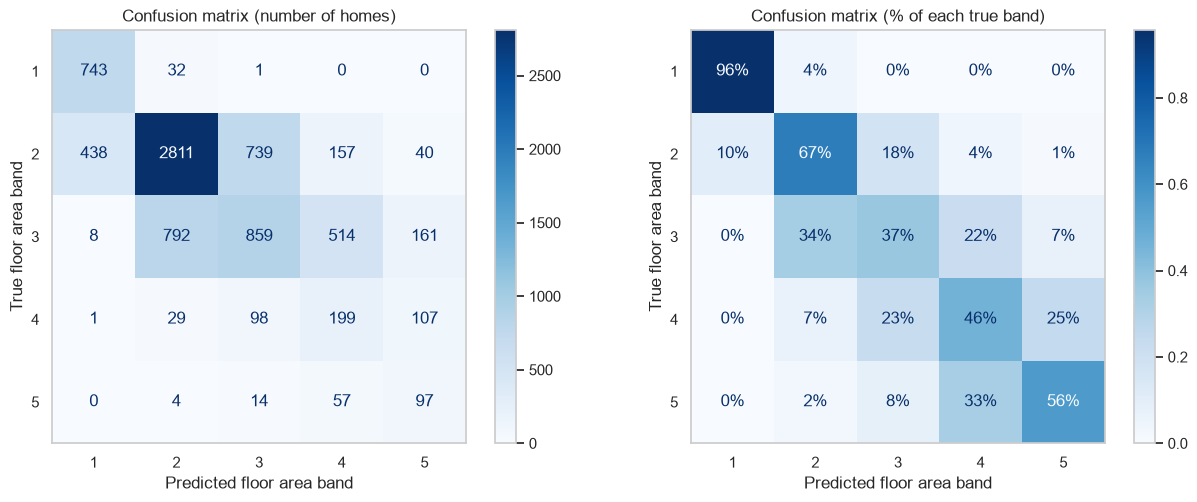

In [18]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

best_model = grid_search.best_estimator_
y_pred_test = best_model.predict(X_test)

print(classification_report(y_test, y_pred_test))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_test, cmap="Blues", ax=axes[0])
axes[0].set_title("Confusion matrix (number of homes)")
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_test, cmap="Blues", normalize="true",
                                        values_format=".0%", ax=axes[1])
axes[1].set_title("Confusion matrix (% of each true band)")
for ax in axes:
    ax.set_xlabel("Predicted floor area band")
    ax.set_ylabel("True floor area band")
    ax.grid(False)
plt.tight_layout()
save_fig("03_04_confusion_matrix")
plt.show()

**Reading the results:**

* **Small homes are easy:** 96% of band-1 homes are recognised.
* **Bands 2 and 3 are confused** with each other the most. Their consumption ranges overlap heavily (see the boxplot in 1.1).
* For large homes (bands 4 and 5), most mistakes go to the **neighbouring** band: a band-5 home is predicted as band 4 in 33% of cases, almost never as band 1 or 2.
* Mistakes of **3 or more bands** are very rare.

## 4.2 Predicted vs actual

Figure saved to ..\figures\03_05_test_results.png


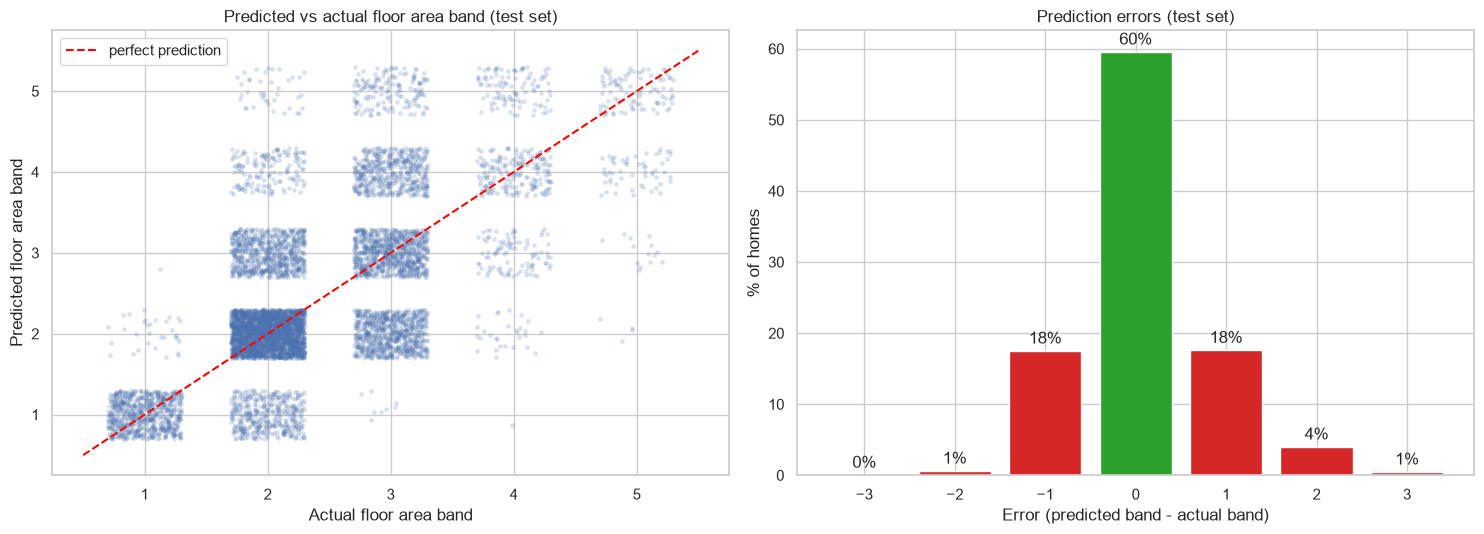

60% of the test homes are placed in exactly the right floor area band
95% of the test homes are placed within ±1 band of their real floor area


In [19]:
band_error = y_pred_test - y_test.to_numpy()                   # +1 = one band too big, -1 = one band too small
jitter = np.random.default_rng(RANDOM_STATE).uniform(-0.3, 0.3, (2, len(y_test)))   # spread the dots a little

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

axes[0].scatter(y_test + jitter[0], y_pred_test + jitter[1], alpha=0.15, s=6)
axes[0].plot([0.5, 5.5], [0.5, 5.5], color="red", linestyle="--", label="perfect prediction")
axes[0].set_xticks(range(1, 6))
axes[0].set_yticks(range(1, 6))
axes[0].set_title("Predicted vs actual floor area band (test set)")
axes[0].set_xlabel("Actual floor area band")
axes[0].set_ylabel("Predicted floor area band")
axes[0].legend()

error_share = pd.Series(band_error).value_counts(normalize=True).sort_index() * 100
axes[1].bar(error_share.index, error_share.values,
            color=["tab:red" if e != 0 else "tab:green" for e in error_share.index])
axes[1].set_title("Prediction errors (test set)")
axes[1].set_xlabel("Error (predicted band - actual band)")
axes[1].set_ylabel("% of homes")
for e, share in error_share.items():
    axes[1].text(e, share + 1, f"{share:.0f}%", ha="center")

plt.tight_layout()
save_fig("03_05_test_results")
plt.show()

exact = (band_error == 0).mean() * 100
within_one = (np.abs(band_error) <= 1).mean() * 100
print(f"{exact:.0f}% of the test homes are placed in exactly the right floor area band")
print(f"{within_one:.0f}% of the test homes are placed within ±1 band of their real floor area")

💡 **Tip:** compare the test macro F1 with the cross-validated one from the grid search. If they are close, the model **generalises** well and the cross-validation was a fair estimate.

# 5. What does the model look at?

Computed in 1 s
Figure saved to ..\figures\03_06_feature_importance.png


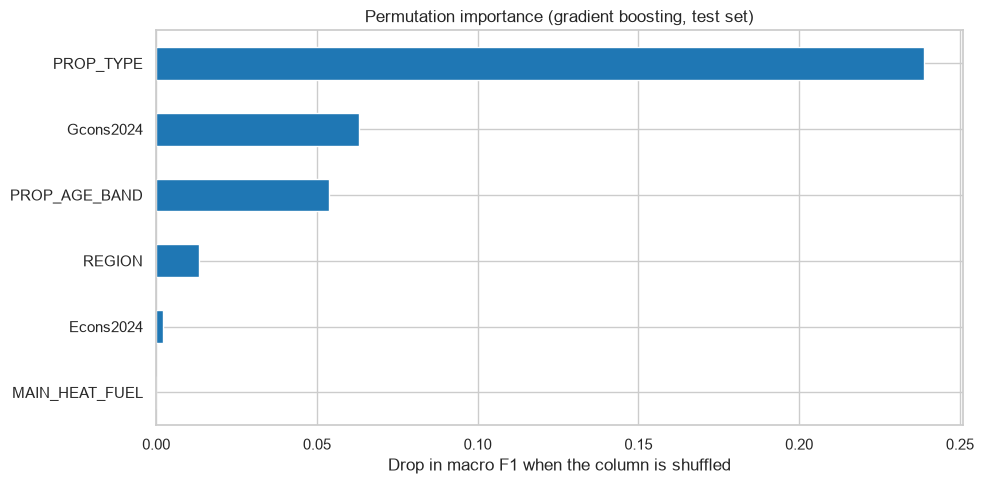

In [20]:
from sklearn.inspection import permutation_importance

start = time.time()
importance = permutation_importance(
    best_model, X_test, y_test,
    scoring="f1_macro", n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1,
)
print(f"Computed in {time.time() - start:.0f} s")

importance_series = pd.Series(importance.importances_mean, index=X_test.columns).sort_values()
importance_series = importance_series.drop("COUNCIL_TAX_BAND")   # not used by the model

fig, ax = plt.subplots(figsize=(10, 5))
importance_series.plot.barh(ax=ax, color="tab:blue")
ax.set_title("Permutation importance (gradient boosting, test set)")
ax.set_xlabel("Drop in macro F1 when the column is shuffled")
plt.tight_layout()
save_fig("03_06_feature_importance")
plt.show()

**Reading the plot:** the model relies mostly on **property type**, then **gas consumption** and **property age**. Electricity and heating fuel add almost nothing. That matches section 3.2: gas consumption is informative, but only once the model knows what *kind* of home it is looking at. The same gas use means a big flat or a small detached house.

# 6. Using the model
## 6.1 Saving and loading the model

In [21]:
model_path = MODEL_DIR / "floor_area_gradient_boosting.joblib"
joblib.dump(best_model, model_path)
print(f"Model saved to {model_path} ({model_path.stat().st_size / 1e6:.1f} MB)")

# Later, or in another notebook / app:
loaded_model = joblib.load(model_path)

Model saved to ..\models\floor_area_gradient_boosting.joblib (1.5 MB)


## 6.2 "If this is the fuel consumption, the floor area will be…"

In [22]:
def predict_floor_area(gas_kwh, elec_kwh, prop_type="Semi detached", age_band=2,
                       region="E12000008", heat_fuel=1):
    # Predict the floor area band of one home and print the probability of each band
    home = pd.DataFrame([{
        "Gcons2024": gas_kwh, "Econs2024": elec_kwh, "PROP_AGE_BAND": age_band,
        "PROP_TYPE": prop_type, "REGION": region, "MAIN_HEAT_FUEL": heat_fuel,
        "COUNCIL_TAX_BAND": None,   # not used by the model
    }])
    band = loaded_model.predict(home)[0]
    probabilities = loaded_model.predict_proba(home)[0]

    print(f"{prop_type}, {REGION_NAMES[region]}: gas {gas_kwh:,} kWh, electricity {elec_kwh:,} kWh")
    print(f"  -> floor area band {band} ({FLOOR_AREA_LABELS[band]})")
    print("  probabilities: " + ", ".join(f"band {b}: {p:.0%}" for b, p in zip(loaded_model.classes_, probabilities)))
    return band


predict_floor_area(gas_kwh=5_000, elec_kwh=2_000, prop_type="Flat")
print()
predict_floor_area(gas_kwh=11_000, elec_kwh=3_000)
print()
predict_floor_area(gas_kwh=25_000, elec_kwh=5_500, prop_type="Detached");   # ";" hides the returned value

Flat, South East: gas 5,000 kWh, electricity 2,000 kWh
  -> floor area band 1 (up to 50 m²)
  probabilities: band 1: 92%, band 2: 7%, band 3: 0%, band 4: 0%, band 5: 0%

Semi detached, South East: gas 11,000 kWh, electricity 3,000 kWh
  -> floor area band 3 (101-150 m²)
  probabilities: band 1: 0%, band 2: 46%, band 3: 49%, band 4: 4%, band 5: 1%

Detached, South East: gas 25,000 kWh, electricity 5,500 kWh
  -> floor area band 4 (151-200 m²)
  probabilities: band 1: 0%, band 2: 1%, band 3: 13%, band 4: 47%, band 5: 39%


Change the numbers and the property type to try your own homes. Property types: `Flat`, `Mid terrace`, `End terrace`, `Semi detached`, `Detached`, `Bungalow`. Regions are coded (for example `E12000007` = London, see `REGION_NAMES`).

## 6.3 The model as a design tool: floor area vs gas consumption

What does the model believe for **every** level of gas consumption? We keep one semi-detached and one detached house fixed, change only the gas consumption, and plot the probability of each floor area band.

Figure saved to ..\figures\03_07_floor_area_vs_gas.png


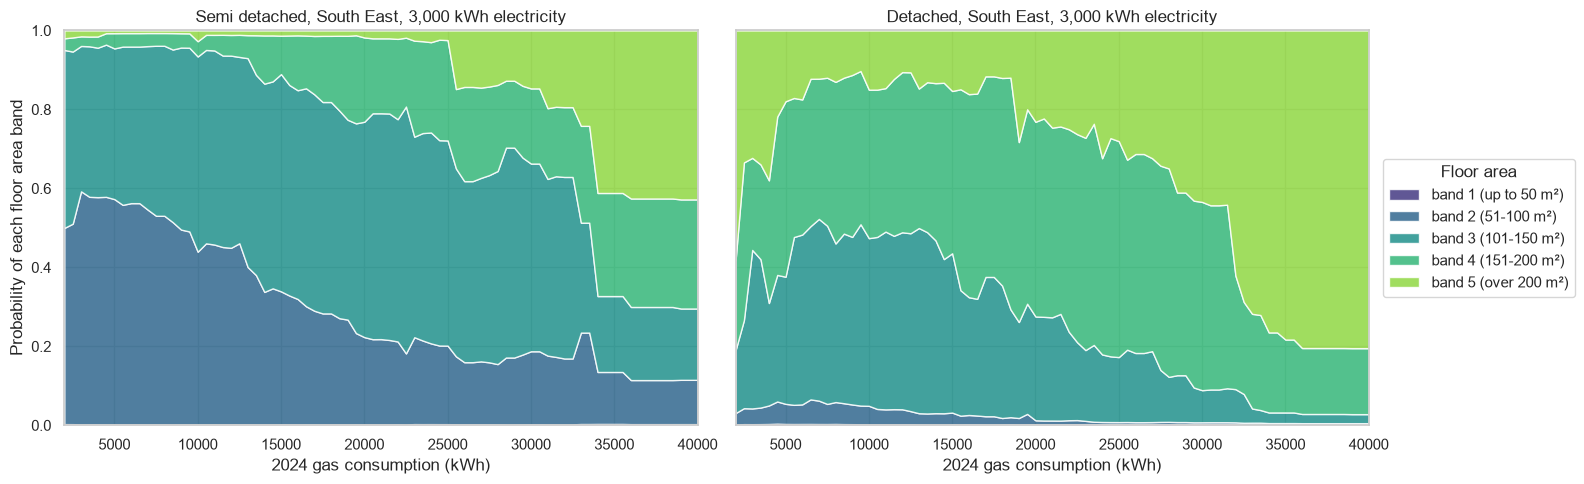

In [23]:
gas_values = np.arange(2_000, 40_001, 500)

fig, axes = plt.subplots(1, 2, figsize=(16, 5), sharey=True)
for ax, prop_type in zip(axes, ["Semi detached", "Detached"]):
    homes = pd.DataFrame({
        "Gcons2024": gas_values, "Econs2024": 3_000, "PROP_AGE_BAND": 2,
        "PROP_TYPE": prop_type, "REGION": "E12000008", "MAIN_HEAT_FUEL": 1, "COUNCIL_TAX_BAND": None,
    })
    probabilities = loaded_model.predict_proba(homes)
    ax.stackplot(gas_values, probabilities.T, alpha=0.85,
                 labels=[f"band {b} ({FLOOR_AREA_LABELS[b]})" for b in loaded_model.classes_],
                 colors=sns.color_palette("viridis", 5))
    ax.set_title(f"{prop_type}, South East, 3,000 kWh electricity")
    ax.set_xlabel("2024 gas consumption (kWh)")
    ax.set_xlim(gas_values.min(), gas_values.max())
    ax.set_ylim(0, 1)
axes[0].set_ylabel("Probability of each floor area band")
axes[1].legend(loc="center left", bbox_to_anchor=(1.01, 0.5), title="Floor area")
plt.tight_layout()
save_fig("03_07_floor_area_vs_gas")
plt.show()

**How to read it:** at each gas consumption on the x-axis, the coloured layers show how likely each floor area band is; they always add up to 100%.

* For the **semi-detached** house, low gas use points to band 2 or 3 (51–150 m²). As gas consumption grows, bands 4 and 5 take over, and above about **34,000 kWh** a band-4 or band-5 home becomes the most likely answer.
* For the **detached** house, the same gas use already points to **larger** bands, because detached houses are bigger on average.
* The steps in the curves come from the gradient boosting trees, which split the gas consumption into ranges. At the extremes (very low or very high gas use) there are few homes in the data, so the model is less reliable there.

This is how a trained model becomes a **design tool**: change one input and see how the estimate moves.

# 7. Conclusions

* **Fuel consumption tells us a lot about floor area, but not everything.** On the test set, the final model places **60%** of homes in exactly the right floor area band and **95%** within ±1 band. The baseline gets 53% right only by always guessing band 2.
* **Gas consumption alone is not enough** (macro F1 ≈ 0.26). It becomes useful when combined with **property type** and **age** (macro F1 ≈ 0.51). The same gas use means different sizes for a flat and a detached house.
* **Class imbalance matters:** `class_weight="balanced"` raises the detection of large homes (bands 4–5) from 8–31% to about 41–58%, at the cost of some accuracy.
* **Limits:** consumption also depends on insulation, number of occupants, heating habits and weather, so the model shows a **correlation**, not a cause. It predicts **bands**, not exact m².

**Next steps:**

* Use more years of consumption (`Gcons2021`–`Gcons2023`) or their average to smooth out unusual years.
* Add `EPC` (energy efficiency rating): a well-insulated large home uses less gas, which confuses the model today.
* Try predicting the **band as an ordered number** (regression, then rounding) and compare the ±1-band accuracy.